# U1 · Volatilidad — Franck Albertson Coaquira Justo

**Proyecto:** CryptoPulse · Grupo 3 · Big Data UPeU 2026-2
**Pregunta central del equipo:** ¿Cómo puede un analista de riesgo anticipar, con 5 a 30 minutos de antelación, condiciones de riesgo en BTC y SOL: volatilidad alta, caídas fuertes, actividad anómala y desacople entre ambos activos?

**Dimensión U1 (batch, descriptiva/diagnóstica + predictiva):** ¿Cuánta volatilidad tuvieron BTC y SOL por mes y por hora del día, y qué volatilidad realizada se puede esperar en los próximos 15 minutos según el comportamiento reciente?

- **Indicador:** Volatilidad realizada a 15 min (%, sin anualizar): media y P95 mensual; volatilidad estimada por un modelo de regresión.
- **Decisión que habilita:** Dimensionar el riesgo de una posición (más volatilidad → menor tamaño o stop más amplio).
- **Fuente batch:** Binance Public Data, velas de 1 minuto BTCUSDT y SOLUSDT, enero 2022 – septiembre 2026 (4 993 759 filas, ZIP con SHA256 verificado).
- **Relación con U2:** el mismo modelo y las mismas variables se aplican en vivo en Grafana, panel *Volatilidad · observada y futura a 15 min*.

Este notebook corre de punta a punta sin intervención manual, sobre los datos reales que deja el pipeline (`scripts/entrenar_producto.ps1`).

## Cómo leer este notebook frente a la rúbrica

**Unidad 1 · evidencia en este notebook**

| Criterio U1 | Peso | Dónde se evidencia |
|---|---:|---|
| 1. Arquitectura seleccionada y justificada | 12 % | Siguiente celda y [Producto U1](https://milagros-hp.github.io/BigData-BTC-SOL/proyecto-sello/u1-producto/) |
| 2. Uso correcto de Spark/PySpark | 16 % | Secciones 1, 2 y 4: esquema, transformaciones, `explain(True)`, agregaciones y RDD |
| 3. Datos particionados en formatos analíticos | 16 % | Sección 3: Parquet, lectura de vuelta y `PartitionFilters` |
| 4. Pipeline batch reproducible | 12 % | Corre de punta a punta con *Run All* o con `scripts/ejecutar_notebooks_u1.py` |
| 5. Componente ML con métricas | 16 % | Sección 6: configuraciones comparadas, tres métricas y ganador guardado |
| 6. Evidencias técnicas | 8 % | Sección 7: `verificacion_u1.json`. **Las capturas con reloj y usuario las toma cada integrante** |
| 7. Sustentación | 20 % | Se evalúa al exponer |

**Unidad 2:** este notebook **no** es el producto de U2. La sección 10 explica cómo este modelo pasa al pipeline en vivo.


### Arquitectura elegida: Lambda

| Capa | Qué hace en CryptoPulse | Por qué |
|---|---|---|
| **Batch** | Procesa 4 993 757 velas válidas de 2022 a 2026 y entrena los modelos | Describir el pasado y entrenar exige el histórico completo |
| **Velocidad** | Aplica esos modelos a cada vela en vivo (Unidad 2) | El analista necesita la señal en segundos |
| **Servicio** | PostgreSQL y Grafana reúnen ambas capas | Una sola vista para decidir |

**Por qué no Kappa:** reprocesar casi cinco años desde un log de eventos sería innecesario, porque el histórico ya existe como archivos mensuales públicos con SHA256 verificable.


## 0. Sesión Spark

In [1]:
import sys, json, math
sys.path.insert(0, "/opt")
from pathlib import Path
from operator import add
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, LongType, DecimalType, StringType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from cryptopulse.core import get_spark, ROOT, CLEAN, ML, FEATURES, TRAIN_END, VALIDATION_END
%matplotlib inline

spark = get_spark("u1-volatilidad", memory="3g", cores=4)
SALIDA = Path("/opt/u1-dimensiones/artifacts/volatilidad")
SALIDA.mkdir(parents=True, exist_ok=True)
print("Spark", spark.version, "| salida:", SALIDA)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 19:41:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | salida: /opt/u1-dimensiones/artifacts/volatilidad


## 1. Extracción con esquema explícito y evaluación perezosa

Se lee un archivo mensual crudo (`BTCUSDT-1m-2025-03.csv`) con `StructType`, sin dejar que Spark adivine tipos. Desde 2025 Binance publica los tiempos en microsegundos, por eso se dividen entre 1000.

In [2]:
ESQUEMA = StructType([StructField("open_time_raw", LongType())] +
    [StructField(c, DecimalType(28, 8)) for c in ["open", "high", "low", "close", "volume"]] +
    [StructField("close_time_raw", LongType()), StructField("quote_asset_volume", DecimalType(28, 8)),
     StructField("number_of_trades", LongType()), StructField("taker_buy_base_volume", DecimalType(28, 8)),
     StructField("taker_buy_quote_volume", DecimalType(28, 8)), StructField("ignore", StringType())])

crudo = spark.read.schema(ESQUEMA).option("mode", "FAILFAST").csv(str(ROOT / "s02-fundamentos/data/raw/BTCUSDT-1m-2025-03.csv"))
velas = (crudo
    .withColumn("open_ms", F.expr("open_time_raw DIV 1000"))
    .withColumn("event_time", F.timestamp_millis("open_ms"))
    .withColumn("rango_pct", 100 * (F.col("high") - F.col("low")) / F.col("open"))
    .withColumn("hora_utc", F.hour("event_time")))
velas.printSchema()

root
 |-- open_time_raw: long (nullable = true)
 |-- open: decimal(28,8) (nullable = true)
 |-- high: decimal(28,8) (nullable = true)
 |-- low: decimal(28,8) (nullable = true)
 |-- close: decimal(28,8) (nullable = true)
 |-- volume: decimal(28,8) (nullable = true)
 |-- close_time_raw: long (nullable = true)
 |-- quote_asset_volume: decimal(28,8) (nullable = true)
 |-- number_of_trades: long (nullable = true)
 |-- taker_buy_base_volume: decimal(28,8) (nullable = true)
 |-- taker_buy_quote_volume: decimal(28,8) (nullable = true)
 |-- ignore: string (nullable = true)
 |-- open_ms: long (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- rango_pct: decimal(38,6) (nullable = true)
 |-- hora_utc: integer (nullable = true)



In [3]:
# Transformaciones: Spark solo arma el plan, todavía no lee el archivo.
resumen_hora = (velas.filter(F.col("number_of_trades") > 0)
    .groupBy("hora_utc")
    .agg(F.count("*").alias("velas"), F.avg("rango_pct").alias("rango_medio_pct"),
         F.sum(F.col("quote_asset_volume").cast("double")).alias("usdt_negociado")))
resumen_hora.explain(True)

== Parsed Logical Plan ==
'Aggregate ['hora_utc], ['hora_utc, 'count(*) AS velas#17, 'avg('rango_pct) AS rango_medio_pct#18, 'sum(cast('quote_asset_volume as double)) AS usdt_negociado#19]
+- Filter (number_of_trades#8L > cast(0 as bigint))
   +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, rango_pct#15, hour(event_time#14, Some(UTC)) AS hora_utc#16]
      +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, (((high#2 - low#3) * cast(100 as decimal(3,0))) / open#1) AS rango_pct#15]
         +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume

In [4]:
# La acción (toPandas) es el momento en que Spark ejecuta el plan de verdad.
tabla_hora = resumen_hora.orderBy("hora_utc").toPandas()
tabla_hora.head(24)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,hora_utc,velas,rango_medio_pct,usdt_negociado
0,0,1860,0.0944359753,3.300926e+09
1,1,1860,0.0939789290,3.104055e+09
2,2,1860,0.0834899495,2.450577e+09
3,3,1860,0.0675862349,1.899215e+09
4,4,1860,0.0583026882,1.907713e+09
5,5,1860,0.0511838355,1.723628e+09
6,6,1860,0.0531504478,1.893365e+09
7,7,1860,0.0584109027,2.285180e+09
8,8,1860,0.0618337543,2.083670e+09
9,9,1860,0.0649230731,2.267155e+09


## 2. Calidad de datos: nulos y duplicados

**Decisión documentada:** no se imputan precios ni se fabrican velas. Una fila con un campo obligatorio nulo se descarta (en S03 va a cuarentena) y, si un mismo minuto aparece dos veces, se conserva una sola fila identificada con `row_number()`.

In [5]:
OBLIGATORIAS = ["open", "high", "low", "close", "volume", "quote_asset_volume", "number_of_trades"]
nulos = velas.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in OBLIGATORIAS])
nulos.show()

ventana = Window.partitionBy("open_ms").orderBy(F.col("number_of_trades").desc())
duplicados = velas.withColumn("fila", F.row_number().over(ventana)).filter("fila > 1").count()
limpio = velas.na.drop(subset=OBLIGATORIAS).dropDuplicates(["open_ms"])
filas_crudas, filas_limpias = velas.count(), limpio.count()
print(f"Duplicados por minuto: {duplicados} | filas crudas {filas_crudas} -> limpias {filas_limpias}")

s03 = json.loads((ROOT / "_runtime/s03.json").read_text(encoding="utf-8"))
print(f"Pipeline completo S03: {s03['input_rows']:,} filas -> {s03['clean_rows']:,} válidas, "
      f"{s03['invalid_rows']} en cuarentena, {s03['gaps']['gaps']} huecos ({s03['gaps']['missing_minutes']:.0f} min)")

+----+----+---+-----+------+------------------+----------------+
|open|high|low|close|volume|quote_asset_volume|number_of_trades|
+----+----+---+-----+------+------------------+----------------+
|   0|   0|  0|    0|     0|                 0|               0|
+----+----+---+-----+------+------------------+----------------+



Duplicados por minuto: 0 | filas crudas 44640 -> limpias 44640
Pipeline completo S03: 4,993,759 filas -> 4,993,757 válidas, 2 en cuarentena, 3 huecos (163 min)


## 3. Parquet particionado y verificación de ida y vuelta

El lago limpio está particionado por `symbol/year/month`. Se filtra la misma partición del archivo crudo y se confirma en el plan físico que Spark solo lee esa carpeta (`PartitionFilters`), y que el conteo coincide con el crudo limpio.

In [6]:
lago = spark.read.parquet(str(CLEAN))
particion = lago.filter((F.col("symbol") == "BTCUSDT") & (F.col("year") == 2025) & (F.col("month") == 3))
plan = particion._jdf.queryExecution().executedPlan().toString()
linea = next(l for l in plan.splitlines() if "PartitionFilters" in l)
print(linea[linea.index("PartitionFilters"):][:260])
assert "PartitionFilters: [" in plan and "BTCUSDT" in plan

filas_particion = particion.count()
print(f"Partición BTCUSDT 2025-03: {filas_particion} filas | crudo limpio: {filas_limpias}")
assert filas_particion == filas_limpias, "La lectura de vuelta no reconcilia con el crudo"

PartitionFilters: [isnotnull(symbol#256), isnotnull(year#257), isnotnull(month#258), (symbol#256 = BTCUSDT), (year#..., PushedFilters: [], ReadSchema: struct<open_time_raw:bigint,open:decimal(28,8),high:decimal(28,8),low:decimal(28,8),close:decimal...


Partición BTCUSDT 2025-03: 44640 filas | crudo limpio: 44640


## 4. Procesamiento con RDD

In [7]:
# Distribución del rango intravela (alto-bajo) en tramos de 0.1 %, con map/reduceByKey.
tramos = (limpio.select("rango_pct").rdd
    .map(lambda r: (min(int(float(r.rango_pct) * 10), 10), 1))
    .reduceByKey(add)
    .sortByKey()
    .collect())
for tramo, n in tramos:
    etiqueta = f">= {tramo/10:.1f} %" if tramo == 10 else f"{tramo/10:.1f}–{(tramo+1)/10:.1f} %"
    print(f"{etiqueta:>12}: {n:6d} velas")

   0.0–0.1 %:  31771 velas
   0.1–0.2 %:   9328 velas
   0.2–0.3 %:   2302 velas
   0.3–0.4 %:    720 velas
   0.4–0.5 %:    269 velas
   0.5–0.6 %:    107 velas
   0.6–0.7 %:     59 velas
   0.7–0.8 %:     37 velas
   0.8–0.9 %:     19 velas
   0.9–1.0 %:      6 velas
    >= 1.0 %:     22 velas


## 5. Análisis descriptivo y diagnóstico (2022 – 2026)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


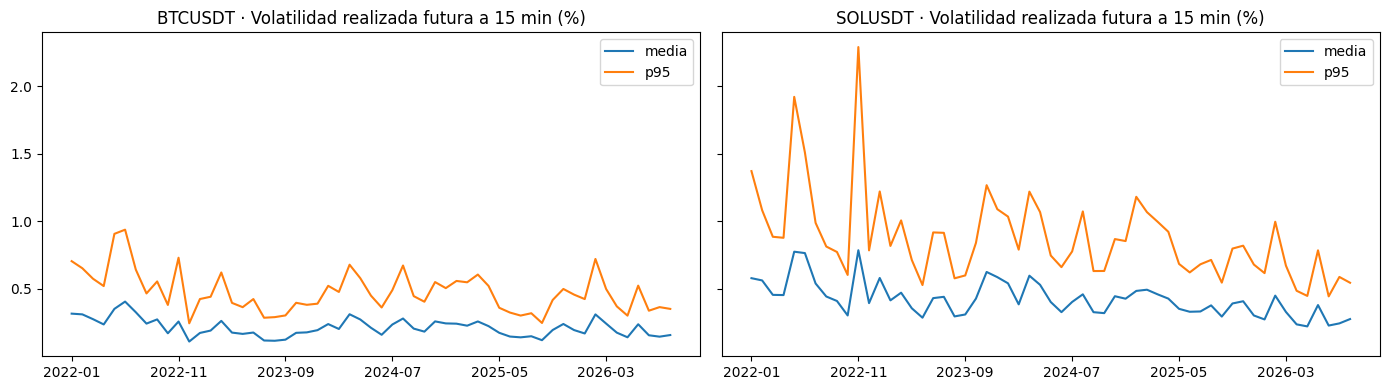

,symbol,mes,media,p95
102,SOLUSDT,2026-04,0.236876,0.485587
103,BTCUSDT,2026-04,0.175574,0.369975
104,SOLUSDT,2026-05,0.221751,0.447391
105,BTCUSDT,2026-05,0.141218,0.301516
106,BTCUSDT,2026-06,0.237623,0.523612
107,SOLUSDT,2026-06,0.379749,0.784965
108,SOLUSDT,2026-07,0.228007,0.444134
109,BTCUSDT,2026-07,0.156126,0.338011
110,BTCUSDT,2026-08,0.145835,0.364527
111,SOLUSDT,2026-08,0.244060,0.587981


In [8]:
datos = (spark.read.parquet(str(ML / "model_dataset"))
    .withColumn("mes", F.date_format(F.timestamp_millis("open_ms"), "yyyy-MM"))
    .withColumn("hora_utc", F.hour(F.timestamp_millis("open_ms")))).cache()
mensual = datos.groupBy("symbol", "mes").agg(F.avg("target_volatility").alias("media"), F.percentile_approx("target_volatility", 0.95).alias("p95")).orderBy("mes").toPandas()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for eje, (activo, grupo) in zip(ejes, mensual.groupby("symbol")):
    grupo.plot(x="mes", y=["media", "p95"], ax=eje, title=f"{activo} · Volatilidad realizada futura a 15 min (%)")
    eje.set_xlabel("")
plt.tight_layout(); plt.show()
mensual.groupby("symbol").tail(6)

**Diagnóstico:** ¿en qué horas UTC se concentra el fenómeno?

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


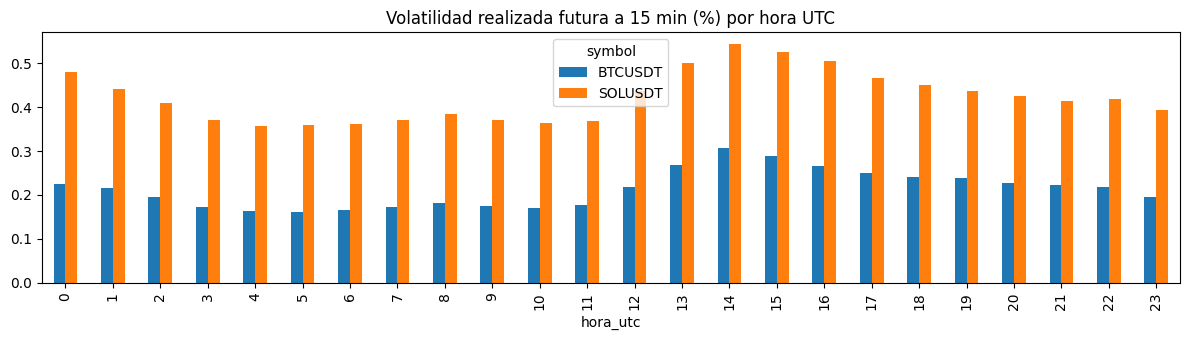

symbol
BTCUSDT    14
SOLUSDT    14
dtype: int32

In [9]:
diag = (datos.groupBy("symbol", "hora_utc").agg((F.avg("target_volatility")).alias("valor"))
    .orderBy("hora_utc").toPandas().pivot(index="hora_utc", columns="symbol", values="valor"))
diag.plot.bar(figsize=(12, 3.5), title="Volatilidad realizada futura a 15 min (%) por hora UTC"); plt.tight_layout(); plt.show()
diag.idxmax()

## 6. Modelo predictivo distribuido (Spark MLlib)

Partición temporal sin fuga de información: **entrenamiento 2022–2024**, **validación 2025**, **prueba enero–septiembre 2026**, con un embargo de 30 minutos entre tramos. El ganador se elige solo con validación; la prueba se usa una vez, al final.

In [10]:
base = datos.withColumnRenamed("target_volatility", "label")
COLUMNAS = FEATURES

In [11]:
entrenamiento = base.filter(F.col("open_ms") + 1800000 < TRAIN_END).cache()
validacion = base.filter((F.col("open_ms") >= TRAIN_END) & (F.col("open_ms") + 1800000 < VALIDATION_END)).cache()
prueba = base.filter(F.col("open_ms") >= VALIDATION_END).cache()
print({"entrenamiento": entrenamiento.count(), "validacion": validacion.count(), "prueba": prueba.count()})

{'entrenamiento': 210392, 'validacion': 70076, 'prueba': 52412}


In [12]:
ensamblador = VectorAssembler(inputCols=COLUMNAS, outputCol="features")
CANDIDATOS = {
    "ridge": LinearRegression(regParam=0.1, elasticNetParam=0.0, maxIter=40),
    "lasso": LinearRegression(regParam=0.01, elasticNetParam=1.0, maxIter=40),
    "random_forest": RandomForestRegressor(numTrees=30, maxDepth=6, minInstancesPerNode=30, seed=26),
}
METRICAS = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m) for m in ("rmse", "mae", "r2")}
media_entrenamiento = entrenamiento.agg(F.avg("label")).first()[0]
REFERENCIA = F.col('rv15')

def evaluar(df):
    df = df.withColumn("prediction", F.greatest(F.lit(0.0), F.col("prediction")))
    return {m: float(e.evaluate(df)) for m, e in METRICAS.items()}

modelos, resultados_val = {}, {}
resultados_val["referencia"] = evaluar(validacion.withColumn("prediction", REFERENCIA))
for nombre, estimador in CANDIDATOS.items():
    modelos[nombre] = Pipeline(stages=[ensamblador, estimador]).fit(entrenamiento)
    resultados_val[nombre] = evaluar(modelos[nombre].transform(validacion))
tabla_val = pd.DataFrame(resultados_val).T.sort_values("rmse")
ganador = min(CANDIDATOS, key=lambda n: resultados_val[n]["rmse"])
print("Referencia:", "persistencia (rv15 actual)", "| ganador en validación:", ganador)
tabla_val

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


Referencia: persistencia (rv15 actual) | ganador en validación: random_forest


,rmse,mae,r2
random_forest,0.139707,0.079066,0.647535
lasso,0.140539,0.081293,0.643329
ridge,0.142146,0.085908,0.635122
referencia,0.160025,0.089369,0.537563


Prueba 2026: RMSE random_forest 0.1285 vs referencia 0.1508 (+14.8 %)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


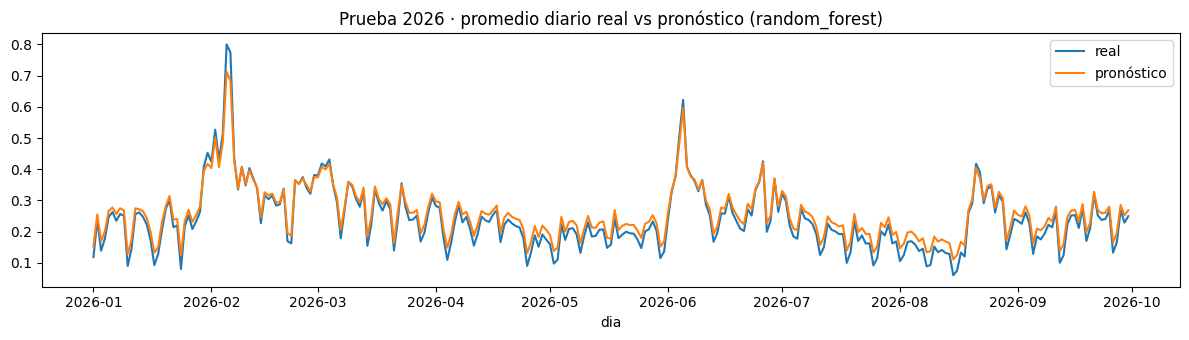

,rmse,mae,r2
random_forest,0.128503,0.077474,0.531463
referencia,0.150802,0.085000,0.354750


In [13]:
predicciones = modelos[ganador].transform(prueba).withColumn("prediction", F.greatest(F.lit(0.0), F.col("prediction")))
resultados_test = {ganador: evaluar(predicciones), "referencia": evaluar(prueba.withColumn("prediction", REFERENCIA))}
mejora = 100 * (1 - resultados_test[ganador]["rmse"] / resultados_test["referencia"]["rmse"])
print(f"Prueba 2026: RMSE {ganador} {resultados_test[ganador]['rmse']:.4f} vs referencia "
      f"{resultados_test['referencia']['rmse']:.4f} ({mejora:+.1f} %)")
diario = (predicciones.withColumn("dia", F.to_date(F.timestamp_millis("open_ms")))
    .groupBy("dia").agg(F.avg("label").alias("real"), F.avg("prediction").alias("pronóstico")).orderBy("dia").toPandas())
diario.plot(x="dia", figsize=(12, 3.5), title=f"Prueba 2026 · promedio diario real vs pronóstico ({ganador})")
plt.tight_layout(); plt.show()
pd.DataFrame(resultados_test).T

In [14]:
# Se guarda el modelo que ganó en validación (no el primero entrenado) y se comprueba que recarga.
ruta = str(SALIDA / "modelo_ganador")
modelos[ganador].write().overwrite().save(ruta)
recargado = PipelineModel.load(ruta)
print("Modelo guardado y recargado:", ruta, "| etapas:", [type(s).__name__ for s in recargado.stages])

Modelo guardado y recargado: /opt/u1-dimensiones/artifacts/volatilidad/modelo_ganador | etapas: ['VectorAssembler', 'RandomForestRegressionModel']


## 7. Registro de la verificación

In [15]:
verificacion = {"dimension": "volatilidad", "integrante": "Franck Albertson Coaquira Justo", "status": "PASS",
    "filas_crudas": filas_crudas, "filas_particion": filas_particion, "duplicados": duplicados,
    "modelo_ganador": ganador, "metricas_validacion": resultados_val, "metricas_prueba": resultados_test,
    "modelo_guardado": str(SALIDA / "modelo_ganador")}
(SALIDA / "verificacion_u1.json").write_text(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float))
spark.stop()

{
  "dimension": "volatilidad",
  "integrante": "Franck Albertson Coaquira Justo",
  "status": "PASS",
  "filas_crudas": 44640,
  "filas_particion": 44640,
  "duplicados": 0,
  "modelo_ganador": "random_forest",
  "metricas_validacion": {
    "referencia": {
      "rmse": 0.1600252323578862,
      "mae": 0.08936884304228822,
      "r2": 0.5375625066741492
    },
    "ridge": {
      "rmse": 0.1421463773192658,
      "mae": 0.08590806507578817,
      "r2": 0.6351219843983098
    },
    "lasso": {
      "rmse": 0.14053860743154828,
      "mae": 0.08129320997941294,
      "r2": 0.6433293302893008
    },
    "random_forest": {
      "rmse": 0.13970749697884588,
      "mae": 0.0790658402702048,
      "r2": 0.6475353803190953
    }
  },
  "metricas_prueba": {
    "random_forest": {
      "rmse": 0.12850349776035702,
      "mae": 0.07747362905732749,
      "r2": 0.5314625717117104
    },
    "referencia": {
      "rmse": 0.15080186195191075,
      "mae": 0.08499988023117329,
      "r2": 0.354

## 8. Las preguntas de mi dimensión y sus respuestas · Franck

### Pregunta U1 (batch)
> ¿Cuánta volatilidad tuvieron BTC y SOL por mes y por hora del día (2022–2026), y qué volatilidad se puede esperar en los próximos 15 minutos?

**Respuesta.** En promedio, la volatilidad realizada a 15 minutos fue de **0,21 % en BTC y 0,42 % en SOL**: Solana se mueve el doble que Bitcoin.

- **Por mes:** los meses más volátiles fueron **junio y mayo de 2022** en BTC (0,41 % y 0,35 %) y **noviembre y mayo de 2022** en SOL (0,79 % y 0,77 %), en plena crisis del mercado cripto. Los más tranquilos, diciembre de 2022 en BTC (0,11 %) y mayo de 2026 en SOL (0,22 %).
- **Por hora del día:** el máximo es a las **14:00–15:00 UTC** (9:00–10:00 en Lima, cuando abre el mercado de EE. UU.) y el mínimo a las **04:00–05:00 UTC**, en ambos activos.
- **Qué se puede esperar en 15 minutos:** el **Random Forest** lo estima con un error (RMSE) de **0,129** en la prueba de 2026, frente a **0,151** de suponer que la volatilidad actual se repite: **14 % menos error**.

### Pregunta U2 (streaming)
> ¿Qué volatilidad tendrá cada activo en los próximos 15 minutos, según lo que está pasando ahora?

**Respuesta.** El mismo Random Forest corre en Spark Streaming y en **cada cierre de minuto** pronostica la volatilidad de BTC y SOL con las últimas 61 velas. Se ve en Grafana, panel **«Volatilidad · Franck»**: línea punteada el pronóstico y puntos la realidad que llegó 15 minutos después. **En vivo:** 432 pronósticos ya evaluados, con un error medio de **0,12 puntos** y un error cuadrático **31 % menor** que el de la referencia (0,036 frente a 0,052).

*Resultados en vivo al 30 de octubre de 2026 (2 días de datos, con la caída del mercado del 29 de octubre). Se actualizan cada minuto en la tabla «En vivo · error real» de Grafana.*

**Decisión que habilita:** ajustar el tamaño de una posición o el margen de un stop según la volatilidad esperada.

## 9. Preguntas del jurado y respuestas

Para practicar: lee la pregunta, respóndela en voz alta y recién después haz clic para ver la respuesta.

### Sobre tu dimensión

<details>
<summary><b>1. ¿Cómo se calcula la volatilidad realizada?</b></summary>

Es 100 por la raíz de la suma de los cuadrados de 15 rendimientos logarítmicos de un minuto, sin anualizar. Se expresa en porcentaje.
</details>

<details>
<summary><b>2. ¿Cuál es tu referencia y por qué es exigente?</b></summary>

La persistencia: suponer que la volatilidad de los próximos 15 minutos será igual a la actual. Es exigente porque la volatilidad se agrupa: si hoy está alta, tiende a seguir alta.
</details>

<details>
<summary><b>3. ¿Qué métricas usas y qué significan?</b></summary>

RMSE (error típico, castiga más los errores grandes), MAE (error promedio) y R² (qué parte de la variación explica el modelo). Mi Random Forest tiene RMSE 0,129 en 2026, frente a 0,151 de la referencia.
</details>

<details>
<summary><b>4. ¿Por qué ganó el Random Forest y no la regresión lineal?</b></summary>

Porque la relación entre las variables y la volatilidad no es lineal: por ejemplo, el efecto de la hora del día cambia según si el mercado ya venía agitado. En validación tuvo el menor RMSE de los tres.
</details>

<details>
<summary><b>5. ¿Por qué SOL es más volátil que BTC?</b></summary>

Es un activo más pequeño y especulativo: con menos dinero se mueve más su precio. En los datos, SOL tiene en promedio el doble de volatilidad que BTC.
</details>


### Sobre el pipeline del notebook (te las pueden hacer a cualquiera)

<details>
<summary><b>6. ¿Por qué lees el CSV con un esquema explícito (StructType) y no dejas que Spark lo adivine?</b></summary>

Porque adivinar obliga a Spark a leer el archivo una vez más y puede equivocarse: por ejemplo, tomar los precios como texto o perder decimales. Con StructType los precios son DecimalType(28,8) desde el inicio, igual que en el contrato de los eventos en vivo.
</details>

<details>
<summary><b>7. ¿Qué muestra explain(True) y en qué momento Spark ejecuta de verdad?</b></summary>

Muestra el plan lógico y el físico que Spark armó con las transformaciones (filter, groupBy). Hasta ahí no leyó ningún dato: es evaluación perezosa. Ejecuta recién con una acción, en el notebook el toPandas() o el count().
</details>

<details>
<summary><b>8. ¿Cómo tratas los nulos y los duplicados?</b></summary>

Cuento los nulos por columna y uso row_number() por minuto para encontrar duplicados antes de quitarlos. La decisión es no imputar precios: una fila inválida se descarta (en el pipeline va a cuarentena) y de un minuto repetido queda una sola fila. En todo el histórico: 4 993 759 filas, 4 993 757 válidas y 0 duplicados.
</details>

<details>
<summary><b>9. ¿Qué demuestra la línea PartitionFilters?</b></summary>

Que Spark solo lee la carpeta symbol/year/month que pedí, no todo el lago. Por eso particionamos por activo, año y mes: son los filtros que siempre usamos. Además el conteo de esa partición coincide con el del CSV crudo limpio, así que la escritura y la lectura de vuelta reconcilian.
</details>

<details>
<summary><b>10. ¿Para qué usas un RDD si ya tienes DataFrames?</b></summary>

Para mostrar el procesamiento distribuido de bajo nivel: map convierte cada vela en un par (tramo, 1) y reduceByKey suma por tramo en paralelo. Es el mismo patrón de MapReduce.
</details>

<details>
<summary><b>11. ¿Por qué separas los datos por fechas y no al azar?</b></summary>

Porque en series de tiempo mezclar al azar deja que el modelo vea el futuro. Entreno con 2022–2024, elijo el ganador con 2025 y pruebo una sola vez con 2026, con 30 minutos de separación para que las etiquetas futuras no crucen el límite.
</details>

<details>
<summary><b>12. ¿Por qué comparas contra una referencia sencilla?</b></summary>

Porque un modelo solo aporta si le gana a una regla simple. Si no le gana, no tiene sentido desplegarlo. Mi referencia aparece en la tabla de métricas junto a los modelos.
</details>

<details>
<summary><b>13. ¿Qué modelo guardaste y cómo sabes que es el correcto?</b></summary>

Guardo el que ganó en validación, no el primero que entrené, y lo recargo con PipelineModel.load para comprobar que funciona. La prueba de 2026 se usa solo al final, para reportar.
</details>


### Conclusión de la Unidad 1

In [16]:
# Conclusión medida: se calcula de esta ejecución, no se escribe a mano.
_filas = []
for _tramo, _clave in (("Validación 2025", "metricas_validacion"), ("Prueba 2026", "metricas_prueba")):
    for _modelo, _valores in verificacion[_clave].items():
        _filas.append({"tramo": _tramo, "modelo": _modelo, **_valores})
display(pd.DataFrame(_filas).round(4))
print("Modelo ganador, elegido solo con validación:", verificacion["modelo_ganador"])
print("Filas crudas:", verificacion["filas_crudas"], "| Filas en la partición:", verificacion["filas_particion"], "| Duplicados:", verificacion["duplicados"])


,tramo,modelo,rmse,mae,r2
0,Validación 2025,referencia,0.1600,0.0894,0.5376
1,Validación 2025,ridge,0.1421,0.0859,0.6351
2,Validación 2025,lasso,0.1405,0.0813,0.6433
3,Validación 2025,random_forest,0.1397,0.0791,0.6475
4,Prueba 2026,random_forest,0.1285,0.0775,0.5315
5,Prueba 2026,referencia,0.1508,0.0850,0.3548


Modelo ganador, elegido solo con validación: random_forest
Filas crudas: 44640 | Filas en la partición: 44640 | Duplicados: 0


## 10. De U1 a U2: del notebook al pipeline en vivo

**Mi dimensión U2:** ¿Qué volatilidad tendrá cada activo en los próximos 15 minutos, según lo que está pasando ahora?

| | Unidad 1 (este notebook) | Unidad 2 (pipeline en vivo) |
|---|---|---|
| **Datos** | Histórico 2022–2026 en Parquet | Velas en vivo por Kafka |
| **Proceso** | Batch con PySpark | Spark Structured Streaming |
| **Modelo** | Se comparan opciones y se elige | Random Forest, aplicado cada minuto |
| **Evaluación** | Prueba reservada de 2026 | Cada pronóstico se compara al madurar su horizonte |
| **Dónde se ve** | Este notebook | Panel *Volatilidad · observada y futura a 15 min* en Grafana |

Dentro de la pregunta central del equipo, esta dimensión mide la **intensidad** del movimiento, sin decir su dirección.

### Dónde está cada criterio de la Unidad 2

| Criterio U2 | Peso | Dónde se evidencia (no es este notebook) |
|---|---:|---|
| 1. Eventos empresariales con Kafka | 12 % | Kafka UI, `market.trades.*`, `trades.py` |
| 2. Eventos IoT/sensores | 10 % | Kafka UI, `market.klines.*`, `producer.py` |
| 3. Streaming con Spark | 14 % | `stream.py`, `pruebas_integracion.ps1` |
| 4. Observabilidad | 12 % | Prometheus y sección *Operación* del tablero |
| 5. Costos y escalado | 8 % | [Producto U2](https://milagros-hp.github.io/BigData-BTC-SOL/proyecto-sello/u2-producto/#costos) |
| 6. Salidas BI/ML | 12 % | Tablero *CryptoPulse · BTC y SOL* |
| 7. Series de tiempo validada | 12 % | *Prueba histórica reservada* y *Evaluación en vivo* |
| 8. Sustentación | 20 % | [Mi parte de la exposición](https://milagros-hp.github.io/BigData-BTC-SOL/u2/) |

**Mis sesiones en la Unidad 2:** S10, S11 y S12 (integración y publicación).

### Resultado en vivo

Medición del 30 de octubre de 2026, de 15:07 a 18:34 UTC. Error absoluto medio; menos es mejor.

| Activo | Evaluados | Modelo | Referencia |
|---|---:|---:|---:|
| BTC | 76 | 0,060 | 0,089 |
| SOL | 75 | 0,084 | 0,108 |

En esta muestra corta, el modelo tuvo menos error que su referencia en ambos activos. Es una muestra de un solo día, así que no reemplaza a la prueba de 2026.


In [17]:
# Estado del pipeline U2, si ya se levantó en este equipo. No es necesario para que este notebook corra.
_runtime = Path("/opt/_runtime")
for _sesion, _tema in [("s06", "Kafka"), ("s07", "Ingesta"), ("s08", "Streaming"), ("s09", "Observabilidad"), ("s10", "Inferencia"), ("s11", "Tablero BI"), ("s12", "Integración")]:
    _archivo = _runtime / f"{_sesion}.json"
    _estado = json.loads(_archivo.read_text()).get("status") if _archivo.exists() else "sin ejecutar en este equipo"
    print(f"{_sesion.upper()} · {_tema}: {_estado}")


S06 · Kafka: PASS
S07 · Ingesta: PASS
S08 · Streaming: PASS
S09 · Observabilidad: PASS
S10 · Inferencia: PASS
S11 · Tablero BI: PASS
S12 · Integración: PASS
